# 02 — Building a target and shooting rays through it

*Weeks 3–4*

In this notebook you build the virtual target and implement the first student-owned analysis function. The ray-marching physics is supplied in `muography.py`; your job is to assemble it into an opacity map.


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../code'))
import numpy as np
import matplotlib.pyplot as plt
import muography as mg
import project_config as cfg
import student_analysis as sa
print('ready')


ready


## The target

`mg.Pyramid` is a square-based pyramid with a 230 m base and 139 m height. The baseline chamber is a **10 m radius (20 m diameter)** sphere centred at `(0, 0, 70)`. These values are stored in `project_config.py` so that all notebooks use the same baseline.


In [2]:
target = mg.Pyramid(
    base=cfg.PYRAMID_BASE_M, height=cfg.PYRAMID_HEIGHT_M,
    density=cfg.ROCK_DENSITY_G_CM3, void_centre=cfg.VOID_CENTRE_M,
    void_radius=cfg.VOID_RADIUS_M, has_void=True,
)
print('inside the void  :', target.density_at(0, 0, 70), 'g/cm^3')
print('inside the rock  :', target.density_at(0, 0, 30), 'g/cm^3')
print('outside entirely :', target.density_at(200, 0, 10), 'g/cm^3')


inside the void  : 0.0012 g/cm^3
inside the rock  : 2.5 g/cm^3
outside entirely : 0.0012 g/cm^3


### YOUR TURN — look at what you have built

Make a vertical slice through the middle of the pyramid and show the chamber. Label the axes in metres and the colourbar in `g/cm³`.


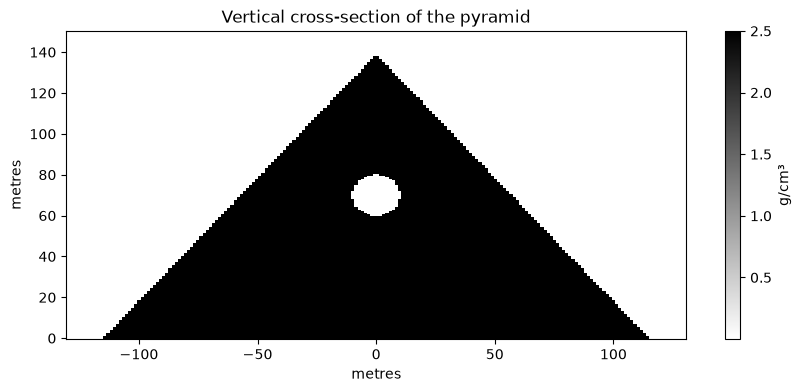

In [3]:
# YOUR TURN
fig, ax = plt.subplots(figsize = (10,4))

x = 0
y = np.linspace (-130,130,200)
z = np.linspace (0,150,200)

newY,newZ = np.meshgrid(y,z)


colors = target.density_at(x,newY,newZ)

img = ax.pcolormesh (newY, newZ, colors, cmap='gray_r', shading = 'auto')

ax.set_title ('Vertical cross-section of the pyramid')
ax.set_xlabel ('metres')
ax.set_ylabel ('metres')

fig.colorbar(img, ax=ax, label ='g/cm³')

plt.show()


## Where does the detector go?

The baseline detector position is `(0, -40, 3)` m. The direction functions use two pointing angles, `ax` and `ay`; together they define the viewing direction.


In [4]:
detector = np.array(cfg.DETECTOR_POSITION_M, dtype=float)
d = mg.direction_from_angles(0.0, 0.0)
print('straight up:', d, '-> zenith', np.degrees(mg.zenith_from_direction(d)), 'deg')


straight up: [0. 0. 1.] -> zenith 0.0 deg


## Ray marching — supplied physics

`mg.trace_one_ray` is the supplied single-ray function. Read it before using it. It walks along a ray in 0.25 m steps and accumulates density × path length.


In [5]:
for deg in [0, 10, 20, 25, 30, 35, 40]:
    d = mg.direction_from_angles(0.0, np.radians(deg))
    X = mg.trace_one_ray(target, detector, d, step=cfg.RAY_STEP_M)
    print(f'ay = {deg:3d} deg   opacity = {X:9.0f} g/cm^2   ({X/100/2.5:6.1f} m of limestone)')


ay =   0 deg   opacity =     21999 g/cm^2   (  88.0 m of limestone)
ay =  10 deg   opacity =     28371 g/cm^2   ( 113.5 m of limestone)
ay =  20 deg   opacity =     34118 g/cm^2   ( 136.5 m of limestone)
ay =  25 deg   opacity =     29620 g/cm^2   ( 118.5 m of limestone)
ay =  30 deg   opacity =     26497 g/cm^2   ( 106.0 m of limestone)
ay =  35 deg   opacity =     26434 g/cm^2   ( 105.7 m of limestone)
ay =  40 deg   opacity =     29933 g/cm^2   ( 119.7 m of limestone)


### YOUR TURN — find the void by hand

Scan `ay` from 15° to 45° in 1° steps. Plot the opacity for the target and for `target.without_void()`. The chamber should create a notch that is absent in the no-void control.


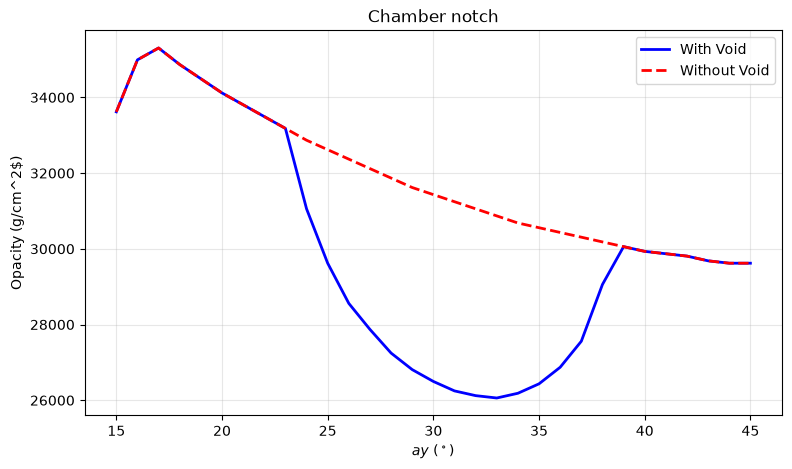

In [6]:
# YOUR TURN

plt.close('all')
plt.figure(figsize=(9,5))

ay_angles = []
op_target = []
op_control = []
# ay = np.linspace (15,45,200)
# op = np.linspace (20000, 38000, 200)



for deg in range (15,46,1):
    d = mg.direction_from_angles(0.0, np.radians(deg))
    op_void = mg.trace_one_ray(target, detector, d, step=cfg.RAY_STEP_M)
    op_no_void = mg.trace_one_ray(target.without_void(), detector, d, step=cfg.RAY_STEP_M)

    ay_angles.append (deg)
    op_target.append (op_void)
    op_control.append(op_no_void)
    
plt.plot (ay_angles, op_target, label = 'With Void', color = 'blue', linewidth = 2)
plt.plot (ay_angles, op_control, label = 'Without Void', color = 'red', linestyle = '--', linewidth = 2)


plt.xlabel(r'$ay\ (^\circ)$')
plt.ylabel (r'Opacity (g/cm^2$)')
plt.title ('Chamber notch')
plt.grid(alpha =0.3, which = 'both')
plt.legend()

plt.show()


## Making a whole image

### YOUR TURN — implement the shared function

Open `code/student_analysis.py` and implement:

```python
opacity_map(target, detector, field_deg=40, step_deg=2)
```

It should build `ax` and `ay` grids, trace one ray per direction using `mg.direction_from_angles` and `mg.trace_one_ray`, and return `(opacity, ax_deg, ay_deg)`. Keep the angle grids in degrees for plotting.

**Important:** this function lives in `student_analysis.py`, not only in this notebook. That makes notebooks 03–05 reproducible from a fresh kernel.


In [7]:
# After implementing the function in code/student_analysis.py, run this cell.
opacity, ax_deg, ay_deg = sa.opacity_map(target, detector)
print('shape:', opacity.shape)


shape: (21, 21)


### YOUR TURN — display and validate

Display the opacity map with `origin='lower'`. Then repeat it for `target.without_void()`. Finally, repeat the map with `ray_step=0.125` m and compare it with the 0.25 m result. The change should be small.


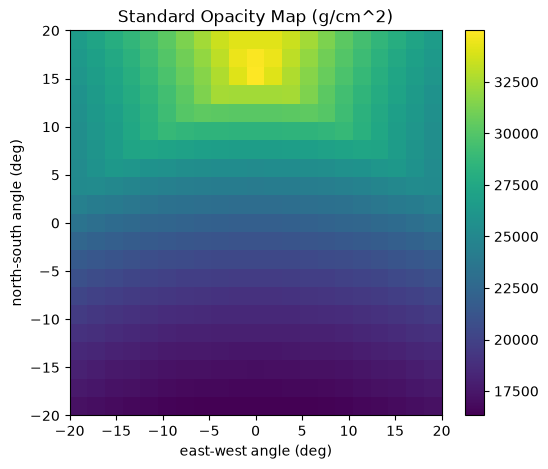

In [13]:
# YOUR TURN

op, ax_deg, ay_deg = sa.opacity_map(target, detector)

plt.figure (figsize=(6,5))
plt.imshow(
    op,
    extent = [ax_deg.min(), ax_deg.max(), ay_deg.min(), ay_deg.max()],
    origin = 'lower',
    aspect = 'auto',
    cmap = 'viridis'
)

plt.colorbar()
plt.xlabel('east-west angle (deg)')
plt.ylabel ('north-south angle (deg)')
plt.title ('Standard Opacity Map (g/cm^2)')
plt.show()


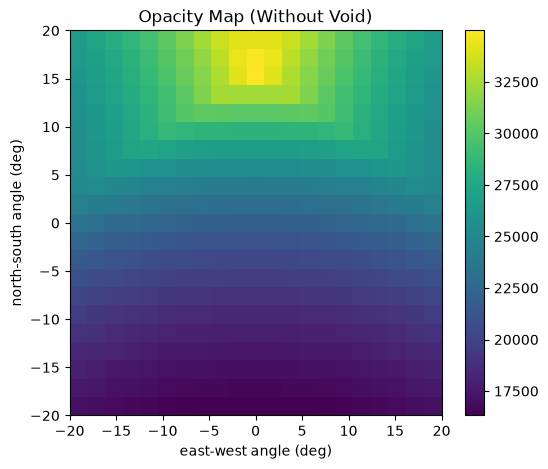

In [ ]:
op_no_void, _, _ = sa.opacity_map(target.without_void(), detector)

plt.figure (figsize=(6,5))
plt.imshow(
    op_no_void,
    extent = [ax_deg.min(), ax_deg.max(), ay_deg.min(), ay_deg.max()],
    origin = 'lower',
    aspect = 'auto',
    cmap = 'viridis'
)
plt.colorbar()
plt.xlabel('east-west angle (deg)')
plt.ylabel ('north-south angle (deg)')
plt.title ('Opacity Map (Without Void) (g/cm^2)')
plt.show()

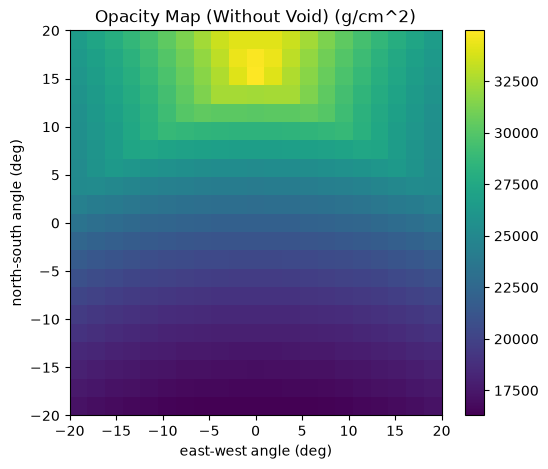

In [14]:
op_half_ray_step, _, _ = sa.opacity_map(target.without_void(), detector, ray_step=0.125)

plt.figure (figsize=(6,5))
plt.imshow(
    op_half_ray_step,
    extent = [ax_deg.min(), ax_deg.max(), ay_deg.min(), ay_deg.max()],
    origin = 'lower',
    aspect = 'auto',
    cmap = 'viridis'
)
plt.colorbar()
plt.xlabel('east-west angle (deg)')
plt.ylabel ('north-south angle (deg)')
plt.title ('Opacity Map (Without Void) (g/cm^2)')
plt.show()